<a href="https://colab.research.google.com/github/PedroMoreira191/CN/blob/main/Atividade1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade 1

**Ambiente:** Python / Google Colab  
**Alunos:** Pedro Oliveira 188198, Felipe Silva 185606
## Objetivos de aprendizagem

O objetivo da atividade é avaliar como as incertezas nas dimensões da peça se propagam para
seu diâmetro, perímetro, área e volume. Os resultados e gráficos deverão auxiliar a empresa
na escolha de um processo de fabricação compatível com a precisão exigida.



## 1. Preparação do ambiente

Usaremos três bibliotecas:

- `math`: constantes e funções matemáticas escalares;
- `numpy`: vetores, operações numéricas e representação de ponto flutuante;
- `matplotlib`: construção de gráficos.

Execute cada célula na ordem. Os comentários iniciados por `#` explicam os comandos Python.

In [ ]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPythonImage
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "font.size": 10,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# A pasta e os arquivos são relativos ao ambiente atual do Colab.
output_dir = Path("atividade_I_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

def mostrar_tabela(tabela, titulo=None):
    """Exibe uma tabela sem índice, com cabeçalho e espaçamento consistentes."""
    estilo = (
        tabela.style
        .hide(axis="index")
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#1f4e79"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                ],
            },
            {
                "selector": "td",
                "props": [("padding", "5px 8px")],
            },
        ])
    )
    if titulo:
        estilo = estilo.set_caption(titulo)
    display(estilo)

print("Ambiente preparado.")

Ambiente preparado.


## 2. Equações principais


Considere a equação

$$E_a= |x − x ̃︁|$$
$$Er =
|x − x ̃︁|/|x|$$

$$E_p = 100Er$$
$$xtrunc =
trunc(10nx)
/10n$$


In [ ]:


# Calcula a distância entre o valor de referência e a aproximação.
def erro_absoluto(x,xr):
  return abs(x - xr)


# Divide o erro absoluto pelo módulo do valor de referência.
def erro_relativo (x,xr):
  return (abs(x-xr) / abs(x))

# Converte o erro relativo em porcentagem.
def erro_percentual (x,xr):
  return 100.0 * (abs(x-xr) / abs(x))

# Função de Truncamento
def truncar(x, n):
  fator = 10**n
  return math.trunc(x * fator) / fator

# Relação de Hagen-Poiseuille
def Q_hagen(r, L, mi, delta_p):
  numerador = math.pi * math.pow(r, 4) * delta_p
  denominador = 8 * mi * L
  return numerador / denominador

## Parte A – truncamento e arredondamento


valor,referência,n casas,aproximação,truncamento,Erro a,Erro r,Erro %
x1,3.141593,0,3,3,0.141593,0.045070,4.507034
x1,3.141593,1,3.1,3.1,0.041593,0.013239,1.323935
x1,3.141593,2,3.14,3.14,0.001593,0.000507,0.050696
x1,3.141593,3,3.142,3.141,0.000407,0.000130,0.012966
x1,3.141593,4,3.1416,3.1415,0.000007,0.000002,0.000234
x2,98.765430,0,99,98,0.234570,0.002375,0.237502
x2,98.765430,1,98.8,98.7,0.034570,0.000350,0.035002
x2,98.765430,2,98.77,98.76,0.004570,0.000046,0.004627
x2,98.765430,3,98.765,98.765,0.000430,0.000004,0.000435
x2,98.765430,4,98.7654,98.7654,0.000030,0.000000,0.000030


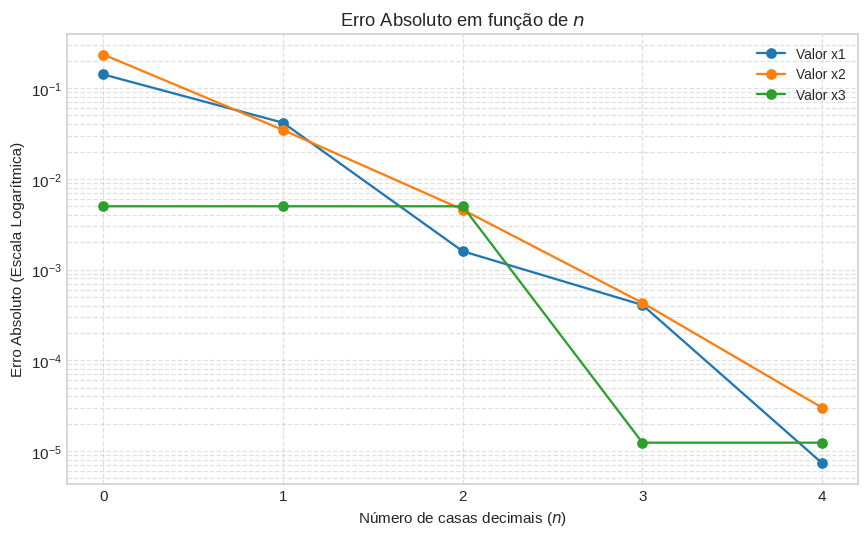

In [ ]:
x1=3.14159265
x2=98.76543
x3 =0.00498765

valores_de_x = {
    "x1": x1,
    "x2": x2,
    "x3": x3
}

linhas_a = []

valores_de_n = [0, 1, 2, 3, 4]

for nome_x, valor_de_x in valores_de_x.items():
    for valor_de_n in valores_de_n:
      valor_arredondado=round(valor_de_x,valor_de_n)
      valor_truncado= truncar(valor_de_x, valor_de_n)
      erro_a= erro_absoluto(valor_de_x, valor_arredondado)
      erro_r= erro_relativo(valor_de_x, valor_arredondado)
      erro_p= erro_percentual(valor_de_x, valor_arredondado)
      linhas_a.append({
                "valor": nome_x,
                "referência": valor_de_x,
                "n casas": valor_de_n,
                "aproximação": f"{valor_arredondado:.{valor_de_n}f}",
                "truncamento": f"{valor_truncado:.{valor_de_n}f}",
                "Erro a": erro_a,
                "Erro r": erro_r,
                "Erro %": erro_p,
            })


tabela_a = pd.DataFrame(linhas_a)
mostrar_tabela(tabela_a, "Parte A - aproximações e erros")

import matplotlib.pyplot as plt

# Configuração da figura
plt.figure(figsize=(8, 5))

# Plotagem das curvas para cada variável (x1, x2, x3)
for nome_x in tabela_a["valor"].unique():
    subconjunto = tabela_a[tabela_a["valor"] == nome_x]
    plt.plot(
        subconjunto["n casas"],
        subconjunto["Erro a"],
        marker="o",
        label=f"Valor {nome_x}",
    )

# Configuração da escala logarítmica e formatação dos eixos
plt.yscale("log")
plt.xlabel("Número de casas decimais ($n$)")
plt.ylabel("Erro Absoluto (Escala Logarítmica)")
plt.title("Erro Absoluto em função de $n$")
plt.xticks(valores_de_n)  # Garante marcas inteiras no eixo X
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()

plt.show()



## 4. Parte B - medidas de pressão arterial

Um equipamento registrou dez medidas consecutivas de pressão arterial sistólica, em mmHg:
121,7; 120,4; 122,1; 119,8; 121,2; 120,9; 122,4; 121,0; 120,2; 121,5.



**B.1 Representação de medidas**

>Quatro séries foram criadas:

1. dados originais;
2. dados arredondados para o inteiro mais próximo;
3. dados truncados para números inteiros;
4. dados arredondados para uma casa decimal.

In [ ]:
# Dados originais das medições
dados_originais = [
    121.7, 120.4,
    122.1, 119.8,
    121.2, 120.9,
    122.4, 121.0,
    120.2, 121.5,
]

# Aproximações
dados_arredondados = [
    round(valor, 0)
    for valor in dados_originais
]

dados_truncados = [
    truncar(valor, 0)
    for valor in dados_originais
]

series = [
    ("Originais", dados_originais),
    ("Arredondados", dados_arredondados),
    ("Truncados", dados_truncados),
]


# Tabela 1: medições
linhas_medicoes = []

for indice in range(len(dados_originais)):
    linhas_medicoes.append({
        "Medição": indice + 1,
        "Original (mmHg)": dados_originais[indice],
        "Arredondado (mmHg)": dados_arredondados[indice],
        "Truncado (mmHg)": dados_truncados[indice],
    })

tabela_medicoes = pd.DataFrame(linhas_medicoes)

def mostrar_tabela_b(tabela, titulo=None):
    """Exibe a tabela com duas casas, preservando a precisão dos erros."""
    formatadores = {}

    for coluna in tabela.select_dtypes(include="number").columns:
        if coluna == "Medição":
            formatadores[coluna] = "{:.0f}"
        elif coluna == "Desvio-padrão amostral (mmHg)":
            formatadores[coluna] = "{:.4f}"
        elif coluna == "Erro absoluto":
            formatadores[coluna] = "{:.4f}"
        elif coluna == "Erro relativo":
            formatadores[coluna] = "{:.6f}"
        elif coluna == "Erro percentual (%)":
            formatadores[coluna] = "{:.4f}"
        else:
            formatadores[coluna] = "{:.2f}"

    estilo = (
        tabela.style
        .hide(axis="index")
        .format(formatadores)
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#1f4e79"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                ],
            },
            {
                "selector": "td",
                "props": [
                    ("padding", "5px 8px"),
                ],
            },
        ])
    )

    if titulo:
        estilo = estilo.set_caption(titulo)

    display(estilo)

mostrar_tabela_b(
    tabela_medicoes,
    "Parte B.1 - representação das medições",
)


# Tabela 2: estatísticas
linhas_estatisticas = []
medias = {}

for nome, lista in series:
    quantidade = len(lista)
    media = sum(lista) / quantidade
    medias[nome] = media

    minimo = min(lista)
    maximo = max(lista)
    amplitude = maximo - minimo

    soma_quadrados = sum(
        (valor - media) ** 2
        for valor in lista
    )

    desvio_padrao = math.sqrt(
        soma_quadrados / (quantidade - 1)
    )

    linhas_estatisticas.append({
        "Série": nome,
        "Média (mmHg)": media,
        "Mínimo (mmHg)": minimo,
        "Máximo (mmHg)": maximo,
        "Amplitude (mmHg)": amplitude,
        "Desvio-padrão amostral (mmHg)": desvio_padrao,
    })

tabela_estatisticas = pd.DataFrame(linhas_estatisticas)

mostrar_tabela_b(
    tabela_estatisticas,
    "Parte B.2 - estatísticas das séries",
)


# Tabela 3: erros das médias
media_referencia = medias["Originais"]
linhas_erros = []

for nome in ["Arredondados", "Truncados"]:
    media_aproximada = medias[nome]

    erro_abs_media = abs(
        media_aproximada - media_referencia
    )

    erro_rel_media = (
        erro_abs_media / abs(media_referencia)
    )

    erro_perc_media = 100 * erro_rel_media

    linhas_erros.append({
        "Série": nome,
        "Média de referência (mmHg)": media_referencia,
        "Média aproximada (mmHg)": media_aproximada,
        "Erro absoluto": erro_abs_media,
        "Erro relativo": erro_rel_media,
        "Erro percentual (%)": erro_perc_media,
    })

tabela_erros = pd.DataFrame(linhas_erros)

mostrar_tabela_b(
    tabela_erros,
    "Parte B.3 - erros das médias",
)

Medição,Original (mmHg),Arredondado (mmHg),Truncado (mmHg)
1,121.70,122.00,121.00
2,120.40,120.00,120.00
3,122.10,122.00,122.00
4,119.80,120.00,119.00
5,121.20,121.00,121.00
6,120.90,121.00,120.00
7,122.40,122.00,122.00
8,121.00,121.00,121.00
9,120.20,120.00,120.00
10,121.50,122.00,121.00


Série,Média (mmHg),Mínimo (mmHg),Máximo (mmHg),Amplitude (mmHg),Desvio-padrão amostral (mmHg)
Originais,121.12,119.80,122.40,2.60,0.8337
Arredondados,121.10,120.00,122.00,2.00,0.8756
Truncados,120.70,119.00,122.00,3.00,0.9487


Série,Média de referência (mmHg),Média aproximada (mmHg),Erro absoluto,Erro relativo,Erro percentual (%)
Arredondados,121.12,121.10,0.0200,0.000165,0.0165
Truncados,121.12,120.70,0.4200,0.003468,0.3468


**B.2 Gráficos obrigatórios**

>Quatro gráficos foram criadas:

1. gráfico das dez medições;
2. gráfico de barras dos erros absolutos das médias;
3. gráfico de barras dos erros percentuais das médias;
4. histograma dos dados originais e dos dados arredondados.

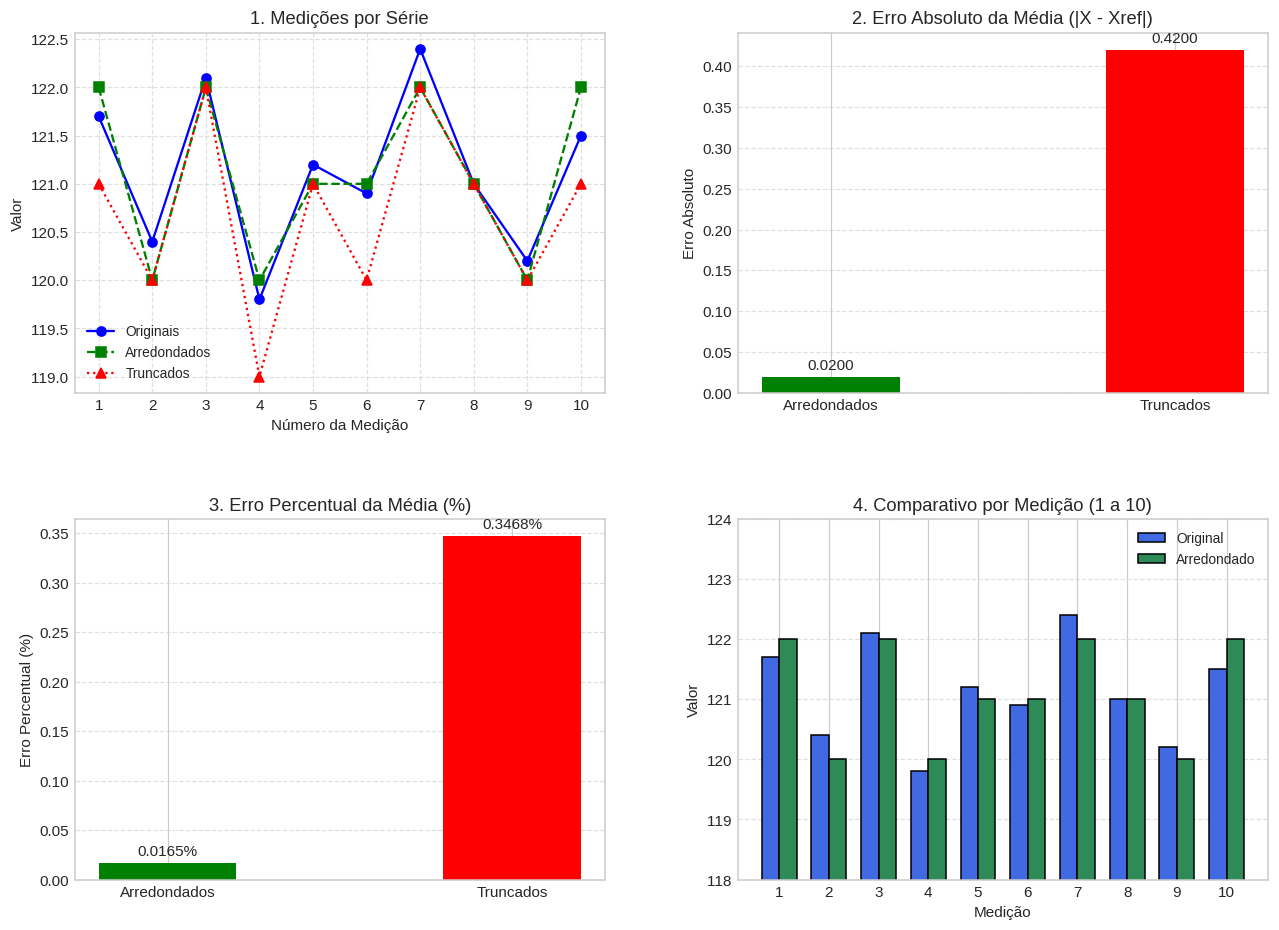

In [ ]:
nomes_erros = ["Arredondados", "Truncados"]
erros_abs = [
    abs(medias["Arredondados"] - media_referencia),
    abs(medias["Truncados"] - media_referencia)
]
erros_perc = [
    (erros_abs[0] / media_referencia) * 100,
    (erros_abs[1] / media_referencia) * 100
]

medicoes = list(range(1, len(dados_originais) + 1))

# Criação da figura com grade 2x2
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# -------------------------------------------------------------
# 1. Gráfico das medições por série
# -------------------------------------------------------------
axs[0, 0].plot(medicoes, dados_originais, marker='o', label='Originais', color='blue', linewidth=1.5)
axs[0, 0].plot(medicoes, dados_arredondados, marker='s', linestyle='--', label='Arredondados', color='green')
axs[0, 0].plot(medicoes, dados_truncados, marker='^', linestyle=':', label='Truncados', color='red')
axs[0, 0].set_title('1. Medições por Série')
axs[0, 0].set_xlabel('Número da Medição')
axs[0, 0].set_ylabel('Valor')
axs[0, 0].set_xticks(medicoes)
axs[0, 0].grid(True, linestyle='--', alpha=0.6)
axs[0, 0].legend()

# -------------------------------------------------------------
# 2. Gráfico de barras dos erros absolutos das médias
# -------------------------------------------------------------
barras_ea = axs[0, 1].bar(nomes_erros, erros_abs, color=['green', 'red'], width=0.4)
axs[0, 1].set_title('2. Erro Absoluto da Média (|X - Xref|)')
axs[0, 1].set_ylabel('Erro Absoluto')
axs[0, 1].grid(axis='y', linestyle='--', alpha=0.6)
for barra in barras_ea:
    altura = barra.get_height()
    axs[0, 1].annotate(f'{altura:.4f}',
                       xy=(barra.get_x() + barra.get_width() / 2, altura),
                       xytext=(0, 3), textcoords="offset points",
                       ha='center', va='bottom')

# -------------------------------------------------------------
# 3. Gráfico de barras dos erros percentuais das médias
# -------------------------------------------------------------
barras_ep = axs[1, 0].bar(nomes_erros, erros_perc, color=['green', 'red'], width=0.4)
axs[1, 0].set_title('3. Erro Percentual da Média (%)')
axs[1, 0].set_ylabel('Erro Percentual (%)')
axs[1, 0].grid(axis='y', linestyle='--', alpha=0.6)
for barra in barras_ep:
    altura = barra.get_height()
    axs[1, 0].annotate(f'{altura:.4f}%',
                       xy=(barra.get_x() + barra.get_width() / 2, altura),
                       xytext=(0, 3), textcoords="offset points",
                       ha='center', va='bottom')

# -------------------------------------------------------------
# 4. Histograma dos dados originais vs arredondados
# -------------------------------------------------------------
largura = 0.35  # Largura de cada barra

# Cria as posições no eixo X para cada conjunto de barras
posicoes_orig = [x - largura/2 for x in medicoes]
posicoes_arr  = [x + largura/2 for x in medicoes]

# Plota as barras lado a lado
axs[1, 1].bar(posicoes_orig, dados_originais, width=largura, label='Original', color='royalblue', edgecolor='black')
axs[1, 1].bar(posicoes_arr,  dados_arredondados, width=largura, label='Arredondado', color='seagreen', edgecolor='black')

axs[1, 1].set_title('4. Comparativo por Medição (1 a 10)')
axs[1, 1].set_xlabel('Medição')
axs[1, 1].set_ylabel('Valor')
axs[1, 1].set_xticks(medicoes)

# Ajusta o limite inferior do eixo Y para destacar as diferenças
axs[1, 1].set_ylim(118, 124)

axs[1, 1].grid(axis='y', linestyle='--', alpha=0.6)
axs[1, 1].legend()

plt.show()

## 5. Parte C - vazão em um tubo de pequeno diâmetro

Para um escoamento laminar idealizado, foi utilizado a relação de Hagen-Poiseuille
$$Q = \frac{\pi r^4 \Delta p}{8 𝜇 L}$$

Foi utilizado como referência
$$r = 0,80 mm, L = 0,2 m, 𝜇 = 3,5 \times 10^{-3} Pas,  Δp = 1200 Pa$$

**C.1 Precisão das variáveis**

>Foi calculado 5 Q's diferentes:

1. todos os valores fornecidos;
2. $r$ arredondado e truncado para uma casa decimal em mm;
3. $µ$ arredondada e truncada para três casas decimais em Pas;
4. $∆p$ arredondada e truncada para centenas de pascal;
5. todas as aproximações simultaneamente.

>O erro foi calculado em cada cenário.

In [ ]:
# Valores de referência
r_orig_mm = 0.80
comprimento_m = 0.20
viscosidade_orig = 3.5e-3
delta_p_orig = 1200.0


# Aproximações
r_arredondado_mm = round(r_orig_mm, 1)
r_truncado_mm = truncar(r_orig_mm, 1)

viscosidade_arredondada = round(viscosidade_orig, 3)
viscosidade_truncada = truncar(viscosidade_orig, 3)

delta_p_arredondado = round(delta_p_orig, -2)

# Truncamento para centenas de pascal
delta_p_truncado = (
    truncar(delta_p_orig / 100, 0) * 100
)


# Cenários analisados
cenarios = [
    (
        "Valores originais (referência)",
        r_orig_mm,
        viscosidade_orig,
        delta_p_orig,
    ),
    (
        "Raio arredondado",
        r_arredondado_mm,
        viscosidade_orig,
        delta_p_orig,
    ),
    (
        "Raio truncado",
        r_truncado_mm,
        viscosidade_orig,
        delta_p_orig,
    ),
    (
        "Viscosidade arredondada",
        r_orig_mm,
        viscosidade_arredondada,
        delta_p_orig,
    ),
    (
        "Viscosidade truncada",
        r_orig_mm,
        viscosidade_truncada,
        delta_p_orig,
    ),
    (
        "Pressão arredondada",
        r_orig_mm,
        viscosidade_orig,
        delta_p_arredondado,
    ),
    (
        "Pressão truncada",
        r_orig_mm,
        viscosidade_orig,
        delta_p_truncado,
    ),
    (
        "Todos arredondados",
        r_arredondado_mm,
        viscosidade_arredondada,
        delta_p_arredondado,
    ),
    (
        "Todos truncados",
        r_truncado_mm,
        viscosidade_truncada,
        delta_p_truncado,
    ),
]


# Vazão de referência
q_referencia = Q_hagen(
    r_orig_mm * 1e-3,
    comprimento_m,
    viscosidade_orig,
    delta_p_orig,
)


# Cálculo das vazões e dos erros
linhas_c = []

for nome, raio_mm, viscosidade, delta_p in cenarios:
    q_calculada = Q_hagen(
        raio_mm * 1e-3,
        comprimento_m,
        viscosidade,
        delta_p,
    )

    erro_absoluto_c = abs(
        q_calculada - q_referencia
    )

    erro_relativo_c = (
        erro_absoluto_c / abs(q_referencia)
    )

    erro_percentual_c = 100 * erro_relativo_c

    linhas_c.append({
        "Cenário": nome,
        "r (mm)": raio_mm,
        "μ (Pa·s)": viscosidade,
        "Δp (Pa)": delta_p,
        "Q (m³/s)": q_calculada,
        "Q (uL/s)": q_calculada * 1e9,
        "Erro absoluto (m³/s)": erro_absoluto_c,
        "Erro relativo": erro_relativo_c,
        "Erro percentual (%)": erro_percentual_c,
    })


tabela_c = pd.DataFrame(linhas_c)


# Formatação da tabela
formatadores_c = {
    "r (mm)": "{:.2f}",
    "μ (Pa·s)": "{:.4e}",
    "Δp (Pa)": "{:.2f}",
    "Q (m³/s)": "{:.6e}",
    "Q (uL/s)": "{:.3f}",
    "Erro absoluto (m³/s)": "{:.6e}",
    "Erro relativo": "{:.6e}",
    "Erro percentual (%)": "{:.4f}",
}


tabela_c_estilizada = (
    tabela_c.style
    .hide(axis="index")
    .format(formatadores_c)
    .set_caption(
        "Parte C - comparação das vazões e dos erros"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1f4e79"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("padding", "6px 10px"),
                ("text-align", "center"),
            ],
        },
    ])
)

display(tabela_c_estilizada)

Cenário,r (mm),μ (Pa·s),Δp (Pa),Q (m³/s),Q (uL/s),Erro absoluto (m³/s),Erro relativo,Erro percentual (%)
Valores originais (referência),0.80,3.5000e-03,1200.00,2.757421e-07,275.742,0.000000e+00,0.000000e+00,0.0000
Raio arredondado,0.80,3.5000e-03,1200.00,2.757421e-07,275.742,0.000000e+00,0.000000e+00,0.0000
Raio truncado,0.80,3.5000e-03,1200.00,2.757421e-07,275.742,0.000000e+00,0.000000e+00,0.0000
Viscosidade arredondada,0.80,4.0000e-03,1200.00,2.412743e-07,241.274,3.446776e-08,1.250000e-01,12.5000
Viscosidade truncada,0.80,3.0000e-03,1200.00,3.216991e-07,321.699,4.595701e-08,1.666667e-01,16.6667
Pressão arredondada,0.80,3.5000e-03,1200.00,2.757421e-07,275.742,0.000000e+00,0.000000e+00,0.0000
Pressão truncada,0.80,3.5000e-03,1200.00,2.757421e-07,275.742,0.000000e+00,0.000000e+00,0.0000
Todos arredondados,0.80,4.0000e-03,1200.00,2.412743e-07,241.274,3.446776e-08,1.250000e-01,12.5000
Todos truncados,0.80,3.0000e-03,1200.00,3.216991e-07,321.699,4.595701e-08,1.666667e-01,16.6667


**C.2 Sensibilidade**

>O raio foi variado de 0,7 a 0,9 mm. Para cada raio, foi comparado $Q$ de referência, $Q$ após arredondar o raio para uma casa decimal e $Q$ após truncá-lo para uma casa decimal.

Foram feitos os seguintes gráficos:
1. Q em função de $r$;
2. erro absoluto de $Q$ em função de $r$;
3. erro relativo de $Q$ em função de $r$;
4. erro percentual de $Q$ em função de $r$.
Explique por que o erro no raio é amplificado na vazão. Relacione sua resposta ao expoente
quatro.

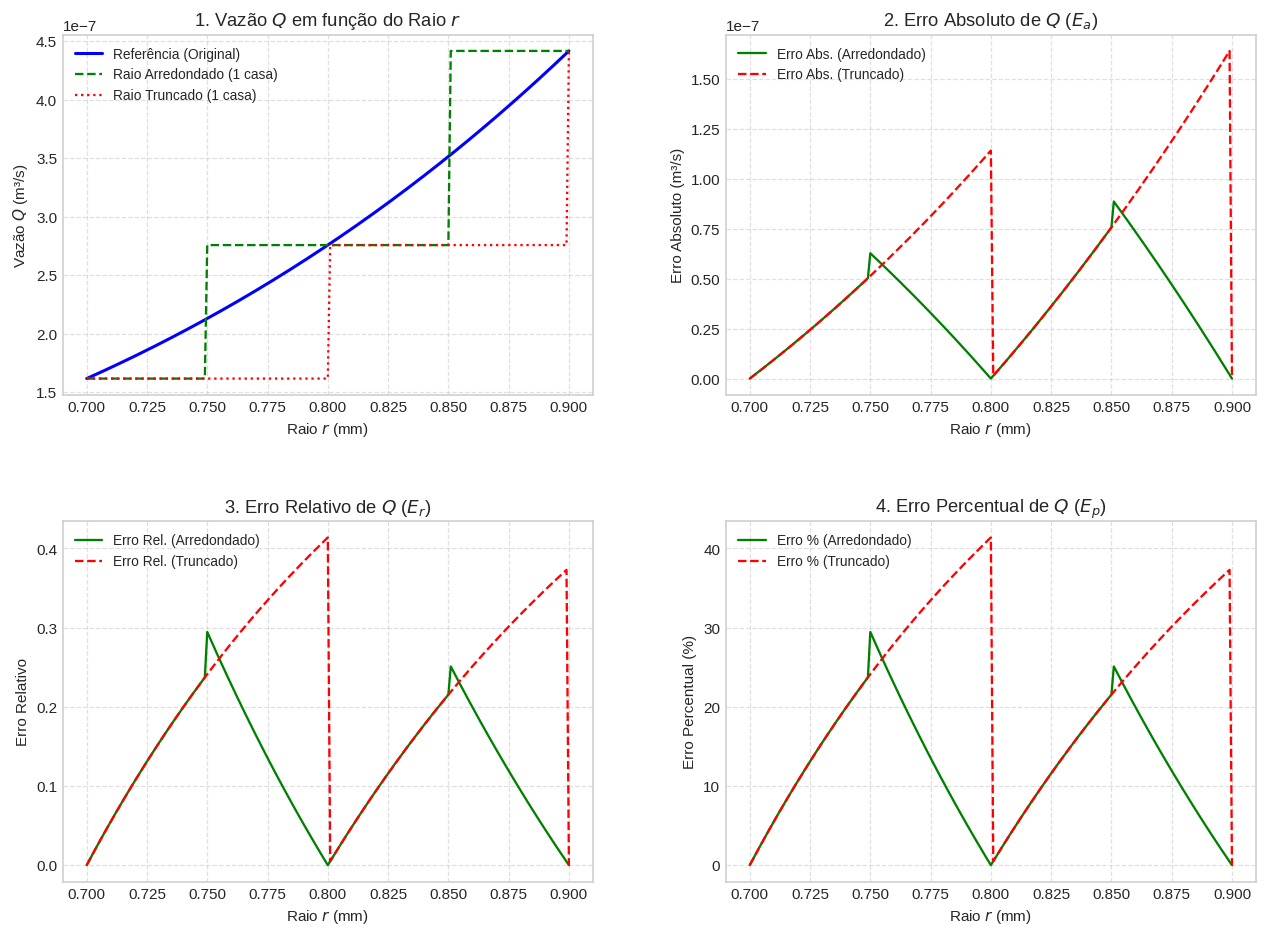

In [ ]:
raios_mm = [0.70 + i * 0.001 for i in range(201)]  # 201 pontos de 0.70 a 0.90 mm

# Define L and mi_orig from the previous section
comprimento_m = 0.20 # L was defined as comprimento_m in hg_ri45kZ3RW
viscosidade_orig = 3.5e-3 # mi_orig was defined as viscosidade_orig in hg_ri45kZ3RW

q_ref_lista = []
q_arr_lista = []
q_trunc_lista = []

ea_arr_lista = []
ea_trunc_lista = []

er_arr_lista = []
er_trunc_lista = []

ep_arr_lista = []
ep_trunc_lista = []

for r_val_mm in raios_mm:
    r_val_orig_m = r_val_mm * 1e-3
    r_val_arr_m  = round(r_val_mm, 1) * 1e-3
    r_val_trunc_m = truncar(r_val_mm, 1) * 1e-3

    # Cálculos de Q (usando L, mi_orig e delta_p_orig já definidos)
    q_r = Q_hagen(r_val_orig_m, comprimento_m, viscosidade_orig, delta_p_orig)
    q_a = Q_hagen(r_val_arr_m, comprimento_m, viscosidade_orig, delta_p_orig)
    q_t = Q_hagen(r_val_trunc_m, comprimento_m, viscosidade_orig, delta_p_orig)

    q_ref_lista.append(q_r)
    q_arr_lista.append(q_a)
    q_trunc_lista.append(q_t)

    # Erros da aproximação por arredondamento
    ea_a = abs(q_a - q_r)
    er_a = ea_a / q_r
    ep_a = er_a * 100

    # Erros da aproximação por truncamento
    ea_t = abs(q_t - q_r)
    er_t = ea_t / q_r
    ep_t = er_t * 100

    ea_arr_lista.append(ea_a)
    ea_trunc_lista.append(ea_t)
    er_arr_lista.append(er_a)
    er_trunc_lista.append(er_t)
    ep_arr_lista.append(ep_a)
    ep_trunc_lista.append(ep_t)

# Configuração e plotagem da grade 2x2 de gráficos
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. Gráfico: Q em função de r
axs[0, 0].plot(raios_mm, q_ref_lista, label='Referência (Original)', color='blue', linewidth=2)
axs[0, 0].plot(raios_mm, q_arr_lista, label='Raio Arredondado (1 casa)', color='green', linestyle='--')
axs[0, 0].plot(raios_mm, q_trunc_lista, label='Raio Truncado (1 casa)', color='red', linestyle=':')
axs[0, 0].set_title('1. Vazão $Q$ em função do Raio $r$')
axs[0, 0].set_xlabel('Raio $r$ (mm)')
axs[0, 0].set_ylabel('Vazão $Q$ (m³/s)')
axs[0, 0].grid(True, linestyle='--', alpha=0.6)
axs[0, 0].legend()

# 2. Gráfico: Erro Absoluto de Q em função de r
axs[0, 1].plot(raios_mm, ea_arr_lista, label='Erro Abs. (Arredondado)', color='green', linewidth=1.5)
axs[0, 1].plot(raios_mm, ea_trunc_lista, label='Erro Abs. (Truncado)', color='red', linestyle='--', linewidth=1.5)
axs[0, 1].set_title('2. Erro Absoluto de $Q$ ($E_a$)')
axs[0, 1].set_xlabel('Raio $r$ (mm)')
axs[0, 1].set_ylabel('Erro Absoluto (m³/s)')
axs[0, 1].grid(True, linestyle='--', alpha=0.6)
axs[0, 1].legend()

# 3. Gráfico: Erro Relativo de Q em função de r
axs[1, 0].plot(raios_mm, er_arr_lista, label='Erro Rel. (Arredondado)', color='green', linewidth=1.5)
axs[1, 0].plot(raios_mm, er_trunc_lista, label='Erro Rel. (Truncado)', color='red', linestyle='--', linewidth=1.5)
axs[1, 0].set_title('3. Erro Relativo de $Q$ ($E_r$)')
axs[1, 0].set_xlabel('Raio $r$ (mm)')
axs[1, 0].set_ylabel('Erro Relativo')
axs[1, 0].grid(True, linestyle='--', alpha=0.6)
axs[1, 0].legend()

# 4. Gráfico: Erro Percentual de Q em função de r
axs[1, 1].plot(raios_mm, ep_arr_lista, label='Erro % (Arredondado)', color='green', linewidth=1.5)
axs[1, 1].plot(raios_mm, ep_trunc_lista, label='Erro % (Truncado)', color='red', linestyle='--', linewidth=1.5)
axs[1, 1].set_title('4. Erro Percentual de $Q$ ($E_p$)')
axs[1, 1].set_xlabel('Raio $r$ (mm)')
axs[1, 1].set_ylabel('Erro Percentual (%)')
axs[1, 1].grid(True, linestyle='--', alpha=0.6)
axs[1, 1].legend()

plt.show()

## 6. Parte D - escoamento em um nanocateter



Vazão Nominal de Referência Q(r): 3.506242e-19 m³/s



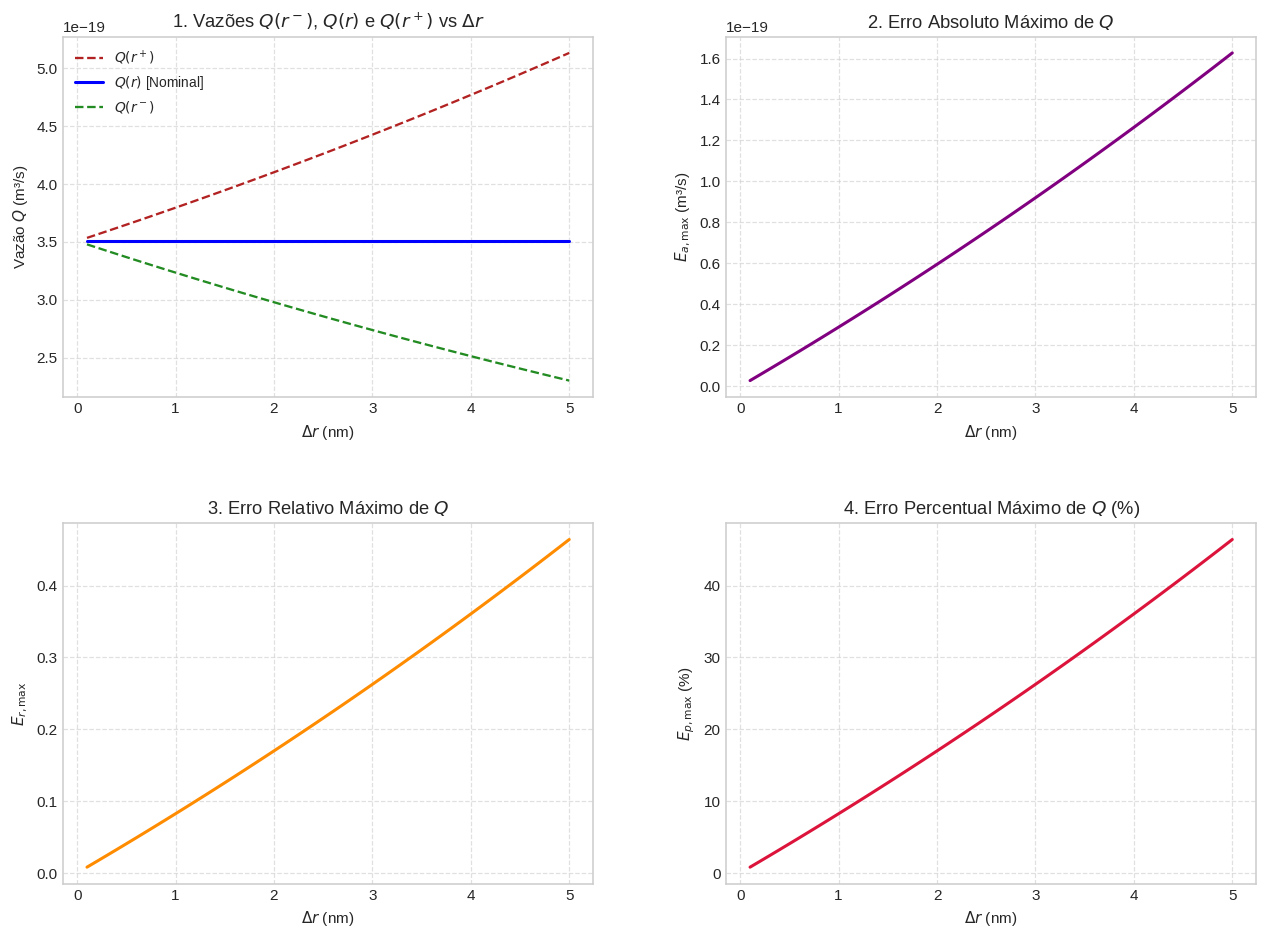

In [ ]:
r_nom_nm = 50.0                # nm
r_nom = r_nom_nm * 1e-9        # m
L = 10.0 * 1e-6                # 10 μm = 10e-6 m
mi = 3.5e-3                    # Pa·s
delta_p = 5000.0               # Pa

# Vazão nominal de referência Q(r)
Q_ref = Q_hagen(r_nom, L, mi, delta_p)
print(f"Vazão Nominal de Referência Q(r): {Q_ref:.6e} m³/s\n")

# 3. Variação de delta_r de 0.1 nm até 5.0 nm (passo 0.1 nm)
delta_r_nm = [round(0.1 * i, 1) for i in range(1, 51)]

q_minus_lista = []
q_ref_lista = []
q_plus_lista = []

ea_max_lista = []
er_max_lista = []
ep_max_lista = []

for dr_nm in delta_r_nm:
    dr_m = dr_nm * 1e-9
    r_minus_m = (r_nom_nm - dr_nm) * 1e-9
    r_plus_m  = (r_nom_nm + dr_nm) * 1e-9

    # Cálculo das vazões
    q_minus = Q_hagen(r_minus_m, L, mi, delta_p)
    q_plus  = Q_hagen(r_plus_m, L, mi, delta_p)

    q_minus_lista.append(q_minus)
    q_ref_lista.append(Q_ref)
    q_plus_lista.append(q_plus)

    # Erro absoluto máximo entre as duas perturbações
    ea_minus = abs(q_minus - Q_ref)
    ea_plus  = abs(q_plus - Q_ref)
    ea_max   = max(ea_minus, ea_plus)

    # Erro relativo e percentual máximos
    er_max = ea_max / Q_ref
    ep_max = er_max * 100

    ea_max_lista.append(ea_max)
    er_max_lista.append(er_max)
    ep_max_lista.append(ep_max)

# 4. Geração dos 4 Gráficos
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Gráfico 1: Q(r-), Q(r) e Q(r+) em função de delta_r
axs[0, 0].plot(delta_r_nm, q_plus_lista, label=r'$Q(r^+)$', color='firebrick', linestyle='--')
axs[0, 0].plot(delta_r_nm, q_ref_lista, label=r'$Q(r)$ [Nominal]', color='blue', linewidth=2)
axs[0, 0].plot(delta_r_nm, q_minus_lista, label=r'$Q(r^-)$', color='forestgreen', linestyle='--')
axs[0, 0].set_title(r'1. Vazões $Q(r^-)$, $Q(r)$ e $Q(r^+)$ vs $\Delta r$')
axs[0, 0].set_xlabel(r'$\Delta r$ (nm)')
axs[0, 0].set_ylabel(r'Vazão $Q$ (m³/s)')
axs[0, 0].grid(True, linestyle='--', alpha=0.6)
axs[0, 0].legend()

# Gráfico 2: Erro Absoluto Máximo
axs[0, 1].plot(delta_r_nm, ea_max_lista, color='purple', linewidth=2)
axs[0, 1].set_title(r'2. Erro Absoluto Máximo de $Q$')
axs[0, 1].set_xlabel(r'$\Delta r$ (nm)')
axs[0, 1].set_ylabel(r'$E_{a,\max}$ (m³/s)')
axs[0, 1].grid(True, linestyle='--', alpha=0.6)

# Gráfico 3: Erro Relativo Máximo
axs[1, 0].plot(delta_r_nm, er_max_lista, color='darkorange', linewidth=2)
axs[1, 0].set_title(r'3. Erro Relativo Máximo de $Q$')
axs[1, 0].set_xlabel(r'$\Delta r$ (nm)')
axs[1, 0].set_ylabel(r'$E_{r,\max}$')
axs[1, 0].grid(True, linestyle='--', alpha=0.6)

# Gráfico 4: Erro Percentual Máximo
axs[1, 1].plot(delta_r_nm, ep_max_lista, color='crimson', linewidth=2)
axs[1, 1].set_title(r'4. Erro Percentual Máximo de $Q$ (%)')
axs[1, 1].set_xlabel(r'$\Delta r$ (nm)')
axs[1, 1].set_ylabel(r'$E_{p,\max}$ (%)')
axs[1, 1].grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# Parâmetros nominais
r_32 = np.float32(50e-9)
L_32 = np.float32(10e-6)
mi_32 = np.float32(3.5e-3)
dp_32 = np.float32(5000.0)
pi_32 = np.float32(np.pi)

r_64 = np.float64(50e-9)
L_64 = np.float64(10e-6)
mi_64 = np.float64(3.5e-3)
dp_64 = np.float64(5000.0)
pi_64 = np.float64(np.pi)


# Cálculo de r^4 e Q
r4_32 = r_32 ** np.float32(4.0)
q_32 = (
    pi_32 * r4_32 * dp_32
    / (np.float32(8.0) * mi_32 * L_32)
)

r4_64 = r_64 ** np.float64(4.0)
q_64 = (
    pi_64 * r4_64 * dp_64
    / (np.float64(8.0) * mi_64 * L_64)
)


# Epsilon de máquina
epsilon_32 = np.finfo(np.float32).eps
epsilon_64 = np.finfo(np.float64).eps


# Tabela 1: valores calculados
tabela_precisao = pd.DataFrame([
    {
        "Representação": "float32",
        "Epsilon de máquina": epsilon_32,
        "r⁴ (m⁴)": float(r4_32),
        "Q (m³/s)": float(q_32),
    },
    {
        "Representação": "float64",
        "Epsilon de máquina": epsilon_64,
        "r⁴ (m⁴)": float(r4_64),
        "Q (m³/s)": float(q_64),
    },
])


formatadores_precisao = {
    "Epsilon de máquina": "{:.6e}",
    "r⁴ (m⁴)": "{:.10e}",
    "Q (m³/s)": "{:.10e}",
}


display(
    tabela_precisao.style
    .hide(axis="index")
    .format(formatadores_precisao)
    .set_caption("Parte D.2 - comparação entre float32 e float64")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1f4e79"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("padding", "6px 10px"),
                ("text-align", "center"),
            ],
        },
    ])
)


# Diferenças entre float32 e float64
diferenca_absoluta_q = abs(
    np.float64(q_32) - q_64
)

diferenca_relativa_q = (
    diferenca_absoluta_q / abs(q_64)
)

diferenca_absoluta_r4 = abs(
    np.float64(r4_32) - r4_64
)

diferenca_relativa_r4 = (
    diferenca_absoluta_r4 / abs(r4_64)
)


tabela_diferencas = pd.DataFrame([
    {
        "Grandeza": "r⁴",
        "Diferença absoluta": diferenca_absoluta_r4,
        "Diferença relativa": diferenca_relativa_r4,
    },
    {
        "Grandeza": "Q",
        "Diferença absoluta": diferenca_absoluta_q,
        "Diferença relativa": diferenca_relativa_q,
    },
])


display(
    tabela_diferencas.style
    .hide(axis="index")
    .format({
        "Diferença absoluta": "{:.6e}",
        "Diferença relativa": "{:.6e}",
    })
    .set_caption("Diferenças entre as representações numéricas")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1f4e79"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("padding", "6px 10px"),
                ("text-align", "center"),
            ],
        },
    ])
)


# Tabela 2: análise de cancelamento numérico
linhas_cancelamento = []

for expoente in range(1, 10):
    razao = 10.0 ** (-expoente)

    # Valor teórico de (1 + x)^4 - 1
    delta_teorico = (
        4 * razao
        + 6 * razao**2
        + 4 * razao**3
        + razao**4
    )

    razao_32 = np.float32(razao)
    delta_r_32 = np.float32(50e-9 * razao_32)

    q_nominal_32 = (
        pi_32 * (r_32 ** np.float32(4.0)) * dp_32
        / (np.float32(8.0) * mi_32 * L_32)
    )

    q_perturbada_32 = (
        pi_32
        * ((r_32 + delta_r_32) ** np.float32(4.0))
        * dp_32
        / (np.float32(8.0) * mi_32 * L_32)
    )

    delta_1 = (
        q_perturbada_32 - q_nominal_32
    ) / q_nominal_32

    delta_2 = (
        np.float32(1.0) + delta_r_32 / r_32
    ) ** np.float32(4.0) - np.float32(1.0)

    if delta_1 == 0 or delta_2 == 0:
        status = "Anulado"
    elif (
        abs(delta_1 - delta_teorico)
        / abs(delta_teorico)
        > 0.05
    ):
        status = "Perda severa"
    else:
        status = "Preciso"

    linhas_cancelamento.append({
        "Δr/r": razao,
        "δ teórico": delta_teorico,
        "δ₁ via subtração": float(delta_1),
        "δ₂ adimensional": float(delta_2),
        "Status": status,
    })


tabela_cancelamento = pd.DataFrame(linhas_cancelamento)


display(
    tabela_cancelamento.style
    .hide(axis="index")
    .format({
        "Δr/r": "{:.0e}",
        "δ teórico": "{:.6e}",
        "δ₁ via subtração": "{:.6e}",
        "δ₂ adimensional": "{:.6e}",
    })
    .set_caption("Análise de cancelamento numérico em float32")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1f4e79"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("padding", "6px 10px"),
                ("text-align", "center"),
            ],
        },
    ])
)

Representação,Epsilon de máquina,r⁴ (m⁴),Q (m³/s)
float32,1.192093e-07,6.2500003960e-30,3.5062423237e-19
float64,2.220446e-16,6.2500000000e-30,3.5062418009e-19


Grandeza,Diferença absoluta,Diferença relativa
r⁴,3.959774e-37,6.335639e-08
Q,5.228628e-26,1.491234e-07


Δr/r,δ teórico,δ₁ via subtração,δ₂ adimensional,Status
1e-01,4.641000e-01,4.641001e-01,4.641001e-01,Preciso
1e-02,4.060401e-02,4.060375e-02,4.060400e-02,Preciso
1e-03,4.006004e-03,4.006010e-03,4.006147e-03,Preciso
1e-04,4.000600e-04,3.998786e-04,4.001856e-04,Preciso
1e-05,4.000060e-05,4.010581e-05,4.005432e-05,Preciso
1e-06,4.000006e-06,3.907368e-06,3.814697e-06,Preciso
1e-07,4.000001e-07,2.211718e-07,4.768372e-07,Perda severa
1e-08,4.000000e-08,0.000000e+00,0.000000e+00,Anulado
1e-09,4.000000e-09,0.000000e+00,0.000000e+00,Anulado


## 7. Parte E - síntese visual

Quadro unico com:
1. Principais valores de pressão e vazão;
2. Comparação entre truncamento e arredondamento;
3. Os três tipos de erros;
4. Sensibilidade de $Q$ ao raio;
5. comparação entre _float32_ e _float64_;
6. Curta conclusão sobre nanocateter.

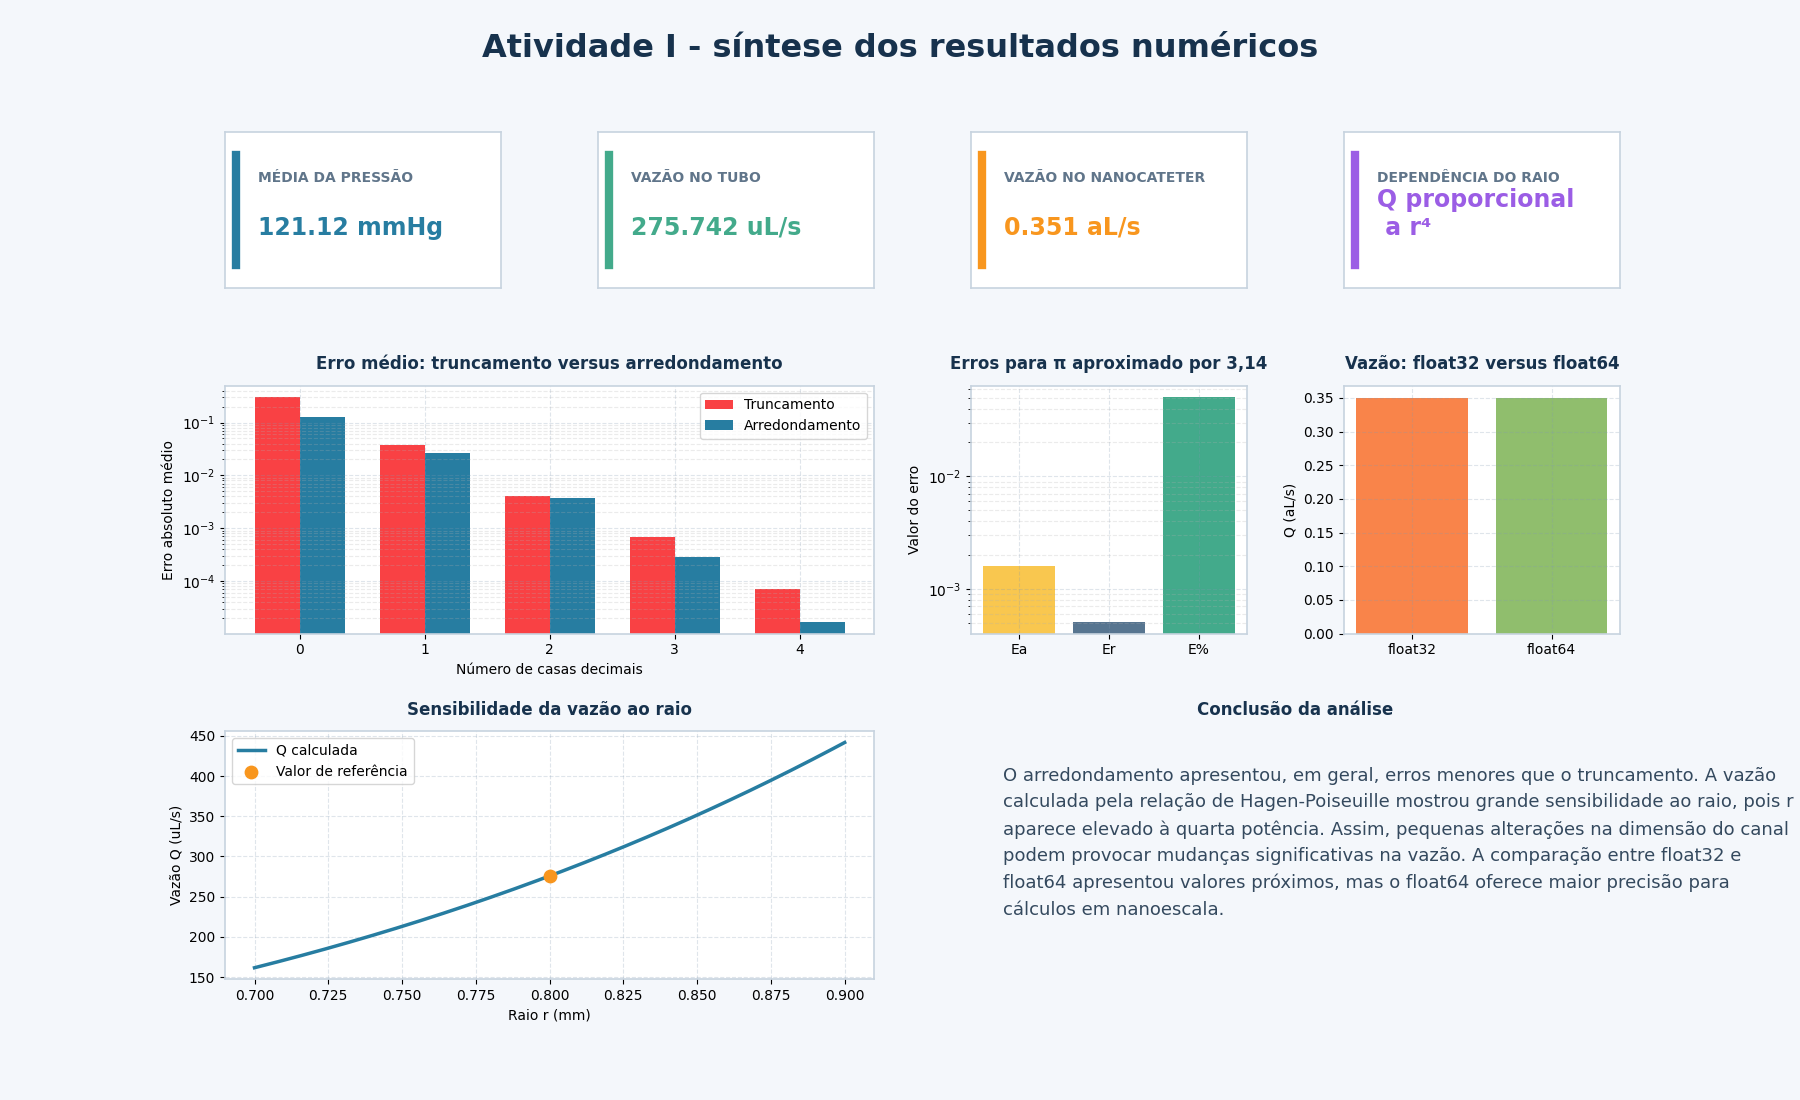

In [ ]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image as IPythonImage
from IPython.display import display


# ============================================================
# 1. Dados e funções utilizados no quadro
# ============================================================

def truncar_local(numero, casas):
    """Trunca um número sem arredondá-lo."""
    fator = 10**casas
    return math.trunc(numero * fator) / fator


def vazao_hagen_poiseuille_local(
    raio_m,
    comprimento_m,
    viscosidade_pa_s,
    delta_p_pa,
):
    """Calcula a vazão pela equação de Hagen-Poiseuille."""
    return (
        math.pi * raio_m**4 * delta_p_pa
        / (8 * viscosidade_pa_s * comprimento_m)
    )


# Dados da Parte A
valores_x = [
    3.14159265,
    98.76543,
    0.00498765,
]

casas_decimais = range(5)

erros_medios_truncamento = []
erros_medios_arredondamento = []

for numero_de_casas in casas_decimais:
    erros_truncamento = []
    erros_arredondamento = []

    for valor in valores_x:
        valor_truncado = truncar_local(
            valor,
            numero_de_casas,
        )

        valor_arredondado = round(
            valor,
            numero_de_casas,
        )

        erro_truncamento = abs(
            valor - valor_truncado
        )

        erro_arredondamento = abs(
            valor - valor_arredondado
        )

        erros_truncamento.append(erro_truncamento)
        erros_arredondamento.append(erro_arredondamento)

    erros_medios_truncamento.append(
        np.mean(erros_truncamento)
    )

    erros_medios_arredondamento.append(
        np.mean(erros_arredondamento)
    )


# Dados da Parte B
dados_pressao = np.array([
    121.7, 120.4,
    122.1, 119.8,
    121.2, 120.9,
    122.4, 121.0,
    120.2, 121.5,
])

media_pressao = dados_pressao.mean()


# Dados da Parte C
raio_tubo_mm = 0.80
comprimento_tubo_m = 0.20
viscosidade_tubo = 3.5e-3
pressao_tubo = 1200.0

vazao_tubo = vazao_hagen_poiseuille_local(
    raio_tubo_mm * 1e-3,
    comprimento_tubo_m,
    viscosidade_tubo,
    pressao_tubo,
)


# Dados da Parte D
raio_nanocateter_nm = 50.0
comprimento_nanocateter_m = 10.0e-6
viscosidade_nanocateter = 3.5e-3
pressao_nanocateter = 5000.0

vazao_nanocateter = vazao_hagen_poiseuille_local(
    raio_nanocateter_nm * 1e-9,
    comprimento_nanocateter_m,
    viscosidade_nanocateter,
    pressao_nanocateter,
)


# Três tipos de erro para pi aproximado por 3,14
pi_referencia = math.pi
pi_aproximado = 3.14

erro_absoluto_pi = abs(
    pi_referencia - pi_aproximado
)

erro_relativo_pi = (
    erro_absoluto_pi / abs(pi_referencia)
)

erro_percentual_pi = 100 * erro_relativo_pi


# Comparação float32 e float64
raio_32 = np.float32(raio_nanocateter_nm * 1e-9)
comprimento_32 = np.float32(comprimento_nanocateter_m)
viscosidade_32 = np.float32(viscosidade_nanocateter)
pressao_32 = np.float32(pressao_nanocateter)

raio_64 = np.float64(raio_nanocateter_nm * 1e-9)
comprimento_64 = np.float64(comprimento_nanocateter_m)
viscosidade_64 = np.float64(viscosidade_nanocateter)
pressao_64 = np.float64(pressao_nanocateter)

q_float32 = (
    np.float32(np.pi)
    * raio_32**np.float32(4)
    * pressao_32
    / (
        np.float32(8)
        * viscosidade_32
        * comprimento_32
    )
)

q_float64 = (
    np.float64(np.pi)
    * raio_64**np.float64(4)
    * pressao_64
    / (
        np.float64(8)
        * viscosidade_64
        * comprimento_64
    )
)


# Sensibilidade da vazão ao raio
raios_tubo_mm = np.linspace(
    0.70,
    0.90,
    201,
)

vazoes_tubo = np.array([
    vazao_hagen_poiseuille_local(
        raio * 1e-3,
        comprimento_tubo_m,
        viscosidade_tubo,
        pressao_tubo,
    )
    for raio in raios_tubo_mm
])


# ============================================================
# 2. Configuração visual do quadro
# ============================================================

fig = plt.figure(
    figsize=(18, 11),
    dpi=100,
    facecolor="#f4f7fb",
)

grade = fig.add_gridspec(
    3,
    4,
    height_ratios=[0.85, 1.35, 1.35],
    hspace=0.45,
    wspace=0.35,
)

fig.suptitle(
    "Atividade I - síntese dos resultados numéricos",
    fontsize=23,
    fontweight="bold",
    color="#17324d",
    y=0.97,
)


def configurar_painel(eixo, titulo):
    """Padroniza a aparência dos painéis do quadro."""
    eixo.set_facecolor("white")

    for spine in eixo.spines.values():
        spine.set_color("#c7d3df")
        spine.set_linewidth(1.2)

    eixo.set_title(
        titulo,
        fontsize=12,
        fontweight="bold",
        color="#17324d",
        pad=12,
    )

    eixo.grid(
        True,
        linestyle="--",
        alpha=0.25,
        color="#829ab1",
    )


# ============================================================
# 3. Cartões superiores
# ============================================================

cartoes = [
    (
        "MÉDIA DA PRESSÃO",
        f"{media_pressao:.2f} mmHg",
        "#277da1",
    ),
    (
        "VAZÃO NO TUBO",
        f"{vazao_tubo * 1e9:.3f} uL/s",
        "#43aa8b",
    ),
    (
        "VAZÃO NO NANOCATETER",
        f"{vazao_nanocateter * 1e18:.3f} aL/s",
        "#f8961e",
    ),
    (
        "DEPENDÊNCIA DO RAIO",
        "Q proporcional\n a r⁴",
        "#9b5de5",
    ),
]

for indice, (titulo, valor, cor) in enumerate(cartoes):
    eixo = fig.add_subplot(grade[0, indice])

    eixo.set_facecolor("white")

    for spine in eixo.spines.values():
        spine.set_color("#c7d3df")
        spine.set_linewidth(1.2)

    eixo.set_xticks([])
    eixo.set_yticks([])

    eixo.axvline(
        x=0.04,
        ymin=0.15,
        ymax=0.85,
        color=cor,
        linewidth=6,
    )

    eixo.text(
        0.12,
        0.68,
        titulo,
        fontsize=10,
        fontweight="bold",
        color="#60758a",
        transform=eixo.transAxes,
    )

    eixo.text(
        0.12,
        0.34,
        valor,
        fontsize=17,
        fontweight="bold",
        color=cor,
        transform=eixo.transAxes,
    )


# ============================================================
# 4. Truncamento versus arredondamento
# ============================================================

eixo = fig.add_subplot(grade[1, 0:2])
configurar_painel(
    eixo,
    "Erro médio: truncamento versus arredondamento",
)

posicoes = np.arange(len(casas_decimais))
largura_barra = 0.36

eixo.bar(
    posicoes - largura_barra / 2,
    erros_medios_truncamento,
    width=largura_barra,
    label="Truncamento",
    color="#f94144",
)

eixo.bar(
    posicoes + largura_barra / 2,
    erros_medios_arredondamento,
    width=largura_barra,
    label="Arredondamento",
    color="#277da1",
)

eixo.set_yscale("log")
eixo.set_xticks(posicoes)
eixo.set_xticklabels(casas_decimais)
eixo.set_xlabel("Número de casas decimais")
eixo.set_ylabel("Erro absoluto médio")
eixo.legend()
eixo.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.25,
)


# ============================================================
# 5. Três tipos de erro
# ============================================================

eixo = fig.add_subplot(grade[1, 2])
configurar_painel(
    eixo,
    "Erros para π aproximado por 3,14",
)

nomes_erros = [
    "Ea",
    "Er",
    "E%",
]

valores_erros = [
    erro_absoluto_pi,
    erro_relativo_pi,
    erro_percentual_pi,
]

eixo.bar(
    nomes_erros,
    valores_erros,
    color=[
        "#f9c74f",
        "#577590",
        "#43aa8b",
    ],
)

eixo.set_yscale("log")
eixo.set_ylabel("Valor do erro")
eixo.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.25,
)


# ============================================================
# 6. Float32 versus float64
# ============================================================

eixo = fig.add_subplot(grade[1, 3])
configurar_painel(
    eixo,
    "Vazão: float32 versus float64",
)

eixo.bar(
    ["float32", "float64"],
    [
        float(q_float32) * 1e18,
        float(q_float64) * 1e18,
    ],
    color=[
        "#f9844a",
        "#90be6d",
    ],
)

eixo.set_ylabel("Q (aL/s)")
eixo.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.25,
)


# ============================================================
# 7. Sensibilidade da vazão ao raio
# ============================================================

eixo = fig.add_subplot(grade[2, 0:2])
configurar_painel(
    eixo,
    "Sensibilidade da vazão ao raio",
)

eixo.plot(
    raios_tubo_mm,
    vazoes_tubo * 1e9,
    color="#277da1",
    linewidth=2.5,
    label="Q calculada",
)

eixo.scatter(
    [raio_tubo_mm],
    [vazao_tubo * 1e9],
    color="#f8961e",
    s=80,
    zorder=5,
    label="Valor de referência",
)

eixo.set_xlabel("Raio r (mm)")
eixo.set_ylabel("Vazão Q (uL/s)")
eixo.legend()


# ============================================================
# 8. Conclusão
# ============================================================

eixo = fig.add_subplot(grade[2, 2:4])
configurar_painel(
    eixo,
    "Conclusão da análise",
)

eixo.axis("off")

conclusao = (
    "O arredondamento apresentou, em geral, erros menores que o "
    "truncamento. A vazão calculada pela relação de Hagen-Poiseuille "
    "mostrou grande sensibilidade ao raio, pois r aparece elevado à "
    "quarta potência. Assim, pequenas alterações na dimensão do canal "
    "podem provocar mudanças significativas na vazão. A comparação "
    "entre float32 e float64 apresentou valores próximos, mas o "
    "float64 oferece maior precisão para cálculos em nanoescala."
)

eixo.text(
    0.05,
    0.55,
    conclusao,
    fontsize=13,
    color="#34495e",
    va="center",
    ha="left",
    wrap=True,
    linespacing=1.6,
    transform=eixo.transAxes,
)


# ============================================================
# 9. Salvamento e exibição do quadro
# ============================================================

output_dir = Path("atividade_I_outputs")
output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

png_path = output_dir / "quadro_unico_resultados.png"

fig.savefig(
    png_path,
    dpi=100,
    facecolor=fig.get_facecolor(),
    edgecolor="none",
)

plt.close(fig)

display(
    IPythonImage(filename=str(png_path))
)


## 8. GIF demonstrativo



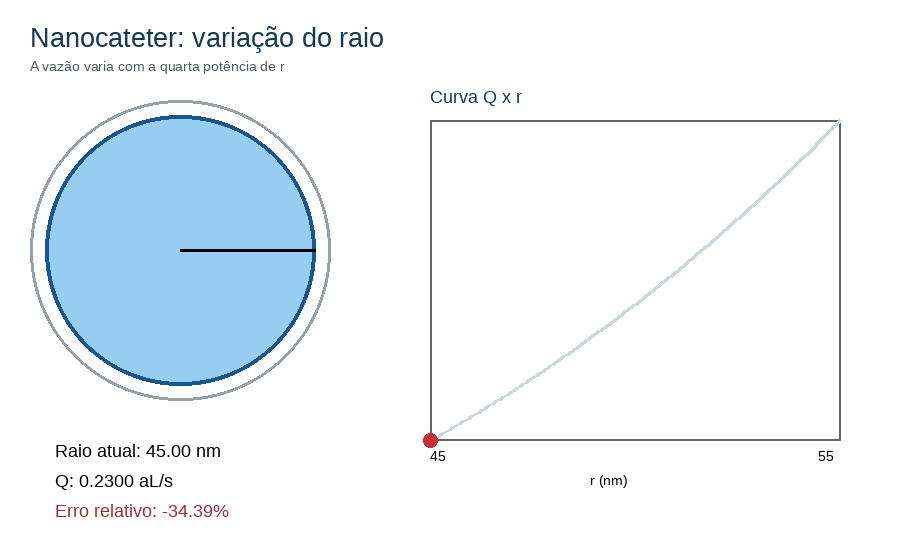

In [ ]:


# Parâmetros do nanocateter, em unidades do SI.
raio_nominal_nm = 50.0
comprimento_m = 10.0e-6
viscosidade_pa_s = 3.5e-3
delta_p_pa = 5000.0

raio_nominal_m = raio_nominal_nm * 1.0e-9


def vazao_hagen_poiseuille(
    raio_m,
    comprimento_m,
    viscosidade_pa_s,
    delta_p_pa,
):
    """Calcula a vazão pela relação de Hagen-Poiseuille."""
    return (
        math.pi * raio_m**4 * delta_p_pa
        / (8.0 * viscosidade_pa_s * comprimento_m)
    )


q_referencia = vazao_hagen_poiseuille(
    raio_nominal_m,
    comprimento_m,
    viscosidade_pa_s,
    delta_p_pa,
)


def carregar_fonte(tamanho):
    """Carrega uma fonte disponível no Colab."""
    for nome_fonte in (
        "DejaVuSans.ttf",
        "LiberationSans-Regular.ttf",
    ):
        try:
            return ImageFont.truetype(nome_fonte, tamanho)
        except OSError:
            continue

    return ImageFont.load_default()


def criar_frame_gif(
    indice,
    total_frames,
    largura=900,
    altura=560,
):
    """Cria um quadro da animação."""
    if total_frames < 2:
        raise ValueError("Use pelo menos dois quadros.")

    raio_nm = 45.0 + 10.0 * indice / (total_frames - 1)
    raio_m = raio_nm * 1.0e-9

    q_atual = vazao_hagen_poiseuille(
        raio_m,
        comprimento_m,
        viscosidade_pa_s,
        delta_p_pa,
    )

    erro_percentual = (
        100.0 * (q_atual - q_referencia) / q_referencia
    )

    imagem = Image.new(
        "RGB",
        (largura, altura),
        "white",
    )
    desenho = ImageDraw.Draw(imagem)

    fonte_titulo = carregar_fonte(27)
    fonte = carregar_fonte(18)
    fonte_pequena = carregar_fonte(14)

    azul_escuro = (20, 55, 90)
    azul = (55, 135, 205)
    cinza = (150, 160, 170)

    desenho.text(
        (30, 22),
        "Nanocateter: variação do raio",
        fill=azul_escuro,
        font=fonte_titulo,
    )

    desenho.text(
        (30, 58),
        "A vazão varia com a quarta potência de r",
        fill=(80, 90, 100),
        font=fonte_pequena,
    )

    # Seção transversal do canal.
    centro_x = 180
    centro_y = 250
    raio_referencia_pixels = 150
    raio_pixels = int(raio_nm * 3.0)

    desenho.ellipse(
        (
            centro_x - raio_referencia_pixels,
            centro_y - raio_referencia_pixels,
            centro_x + raio_referencia_pixels,
            centro_y + raio_referencia_pixels,
        ),
        outline=cinza,
        width=3,
    )

    desenho.ellipse(
        (
            centro_x - raio_pixels,
            centro_y - raio_pixels,
            centro_x + raio_pixels,
            centro_y + raio_pixels,
        ),
        fill=(150, 205, 240),
        outline=(25, 85, 145),
        width=4,
    )

    desenho.line(
        (
            centro_x,
            centro_y,
            centro_x + raio_pixels,
            centro_y,
        ),
        fill=(0, 0, 0),
        width=3,
    )

    desenho.text(
        (55, 440),
        f"Raio atual: {raio_nm:.2f} nm",
        fill=(0, 0, 0),
        font=fonte,
    )

    desenho.text(
        (55, 470),
        f"Q: {q_atual * 1e18:.4f} aL/s",
        fill=(0, 0, 0),
        font=fonte,
    )

    desenho.text(
        (55, 500),
        f"Erro relativo: {erro_percentual:+.2f}%",
        fill=(160, 45, 45),
        font=fonte,
    )

    # Gráfico Q em função do raio.
    x0 = 430
    y0 = 120
    largura_grafico = 410
    altura_grafico = 320

    raios_totais = np.linspace(45.0, 55.0, 200)

    q_total = np.array([
        vazao_hagen_poiseuille(
            raio * 1.0e-9,
            comprimento_m,
            viscosidade_pa_s,
            delta_p_pa,
        )
        for raio in raios_totais
    ]) * 1e18

    q_minimo = q_total.min()
    q_maximo = q_total.max()

    desenho.rectangle(
        (
            x0,
            y0,
            x0 + largura_grafico,
            y0 + altura_grafico,
        ),
        outline=(100, 100, 100),
        width=2,
    )

    desenho.text(
        (x0, y0 - 34),
        "Curva Q x r",
        fill=azul_escuro,
        font=fonte,
    )

    desenho.text(
        (x0 + 160, y0 + altura_grafico + 32),
        "r (nm)",
        fill=(0, 0, 0),
        font=fonte_pequena,
    )

    def ponto_grafico(raio, vazao):
        """Converte os valores físicos em coordenadas do gráfico."""
        x = x0 + int(
            (raio - 45.0) / 10.0 * largura_grafico
        )

        y = y0 + altura_grafico - int(
            (vazao - q_minimo)
            / (q_maximo - q_minimo)
            * altura_grafico
        )

        return x, y

    curva_completa = [
        ponto_grafico(raio, vazao)
        for raio, vazao in zip(raios_totais, q_total)
    ]

    desenho.line(
        curva_completa,
        fill=(205, 215, 225),
        width=3,
    )

    raios_progressivos = np.linspace(
        45.0,
        raio_nm,
        indice + 1,
    )

    q_progressiva = [
        vazao_hagen_poiseuille(
            raio * 1.0e-9,
            comprimento_m,
            viscosidade_pa_s,
            delta_p_pa,
        ) * 1e18
        for raio in raios_progressivos
    ]

    pontos_progressivos = [
        ponto_grafico(raio, vazao)
        for raio, vazao in zip(
            raios_progressivos,
            q_progressiva,
        )
    ]

    if len(pontos_progressivos) > 1:
        desenho.line(
            pontos_progressivos,
            fill=azul,
            width=5,
        )

    px, py = pontos_progressivos[-1]

    desenho.ellipse(
        (
            px - 7,
            py - 7,
            px + 7,
            py + 7,
        ),
        fill=(200, 50, 50),
    )

    desenho.text(
        (x0, y0 + altura_grafico + 8),
        "45",
        fill=(0, 0, 0),
        font=fonte_pequena,
    )

    desenho.text(
        (
            x0 + largura_grafico - 22,
            y0 + altura_grafico + 8,
        ),
        "55",
        fill=(0, 0, 0),
        font=fonte_pequena,
    )

    return imagem


# Criação do GIF.
numero_de_quadros = 40

frames = [
    criar_frame_gif(
        indice,
        numero_de_quadros,
    )
    for indice in range(numero_de_quadros)
]

output_dir = Path("atividade_I_outputs")
output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

gif_path = output_dir / "nanocateter_vazao_raio.gif"

frames[0].save(
    gif_path,
    format="GIF",
    save_all=True,
    append_images=frames[1:],
    duration=120,
    loop=0,
)

display(IPythonImage(filename=str(gif_path)))

### Questões para discussão

1. Qual foi o erro percentual introduzido na medida do raio?
2. Qual foi o erro percentual observado no volume?
3. Por que o erro no volume é aproximadamente três vezes maior?
4. A aproximação linear fornece exatamente o mesmo resultado do cálculo completo?

## 9. Entrega

